# Lab 7: Naive Bayes — From Scratch to Bayes Optimal
### (Student Worksheet)

**Objective:** Classify sentences from biomedical abstracts into their rhetorical role
(BACKGROUND, OBJECTIVE, METHODS, RESULTS, CONCLUSIONS). You will implement Multinomial Naive
Bayes yourself in NumPy, **verify it against scikit-learn**, and then explore how smoothing,
feature representation and model combination change what the classifier can do.

**Dataset:** PubMed 20k RCT — 180,040 labelled training sentences.

**How this notebook works:** Sections 1-2 are fully worked — run them as-is. From Section 3
onward, cells marked **`# TODO`** give instructions but no solution code. Several TODOs name an
**exact variable or method**, because later cells depend on that name. Work through the
sections in order.

---
## 1. Setup & Your Assignment

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

plt.rcParams["figure.dpi"] = 110

Set `STUDENT_ID` to **your own SRN**. Its last three digits set the size of the training
subsample used in Part C, so your Part C numbers will differ based on SRN.

In [4]:
from google.colab import files

uploaded = files.upload()

Saving train.7z to train.7z
Saving train.txt to train.txt
Saving test.txt to test.txt
Saving dev.txt to dev.txt


In [2]:
STUDENT_ID = "PES2UG24CS300"

last_three = int(STUDENT_ID[-3:])
SAMPLE_SIZE = 10_000 + last_three
SEED = 42

print(f"Student ID       : {STUDENT_ID}")
print(f"Part C subsample : {SAMPLE_SIZE:,} training sentences")

Student ID       : PES2UG24CS300
Part C subsample : 10,300 training sentences


---
## 2. Load the Data


Upload `train.txt`, `dev.txt` and `test.txt` from the PubMed 20k RCT dataset next to this
notebook first.

| Split | Purpose |
|---|---|
| **train** | Fits the model — counts the words. |
| **dev** | Chooses hyperparameters (`alpha`, n-gram range). |
| **test** | Scored **once**, at the end. Never used to make a choice. |

In [5]:
def load_pubmed_rct_file(filepath):
    """Read one PubMed 20k RCT .txt file into a DataFrame of (label, sentence)."""
    labels, sentences = [], []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or "\t" not in line:
                continue                      # skips '###<id>' lines and blanks
            label, sent = line.split("\t", maxsplit=1)
            labels.append(label)
            sentences.append(sent)
    return pd.DataFrame({"label": labels, "sentence": sentences})


dir_path = "./"
train_df = load_pubmed_rct_file(os.path.join(dir_path, "train.txt"))
dev_df   = load_pubmed_rct_file(os.path.join(dir_path, "dev.txt"))
test_df  = load_pubmed_rct_file(os.path.join(dir_path, "test.txt"))

X_train, y_train = train_df["sentence"], train_df["label"]
X_dev,   y_dev   = dev_df["sentence"],   dev_df["label"]
X_test,  y_test  = test_df["sentence"],  test_df["label"]
target_names = sorted(y_train.unique())

print(f"Train : {len(train_df):,}")
print(f"Dev   : {len(dev_df):,}")
print(f"Test  : {len(test_df):,}")
print(f"Classes: {target_names}")

Train : 180,040
Dev   : 30,212
Test  : 30,135
Classes: ['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS']


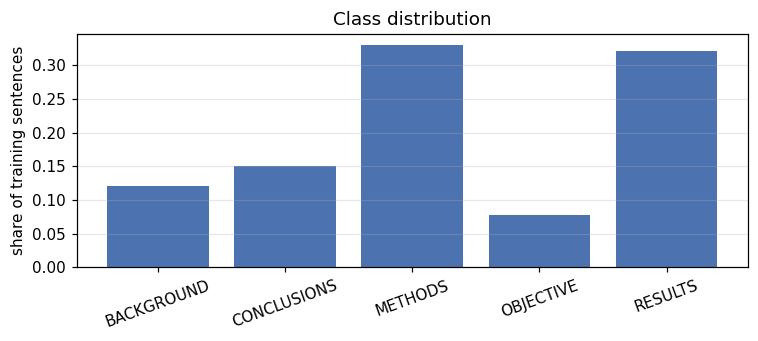

label
BACKGROUND     0.121
CONCLUSIONS    0.151
METHODS        0.330
OBJECTIVE      0.077
RESULTS        0.322

Always-predict-'METHODS' accuracy would be 0.330
Two example sentences:
  [BACKGROUND] Emotional eating is associated with overeating and the development of obesity ....
  [CONCLUSIONS] Low-dose oral prednisolone had both a short-term and a longer sustained effect resulting i...


In [6]:
dist = y_train.value_counts(normalize=True).reindex(target_names)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index, dist.values, color="#4c72b0")
ax.set_ylabel("share of training sentences")
ax.set_title("Class distribution")
ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

print(dist.round(3).to_string())
print(f"\nAlways-predict-'{dist.idxmax()}' accuracy would be {dist.max():.3f}")
print("Two example sentences:")
for lab in target_names[:2]:
    print(f"  [{lab}] {train_df[train_df.label == lab].sentence.iloc[0][:90]}...")

**Answer:** Plain accuracy can be misleading because the model may perform well on common labels while missing less frequent labels. Macro-F1 calculates precision and recall for each class, combines them into an F1 score, and averages those class scores equally, so rare classes matter just as much as common ones. I would expect **OBJECTIVE** or **CONCLUSIONS** to be challenging because these roles can use language similar to BACKGROUND or RESULTS; the class distribution and confusion matrix should be used to check this expectation.

---
## 3. Multinomial Naive Bayes, From Scratch

### Concept

Naive Bayes picks the class with the highest posterior probability given the words in the
sentence. By Bayes' rule, and dropping the evidence term (the same for every class):

$$\hat{c} = \arg\max_{c}\; P(c) \prod_{i} P(w_i \mid c)^{x_i}$$

where $x_i$ is how many times word $i$ appears. The "naive" part is that product: it assumes
words are **conditionally independent** given the class, which is plainly false for language
("randomized" and "controlled" are not independent) but works well anyway.

**Everything happens in log space.** A sentence of 25 words multiplies 25 probabilities, each
perhaps $10^{-5}$ — the result underflows to exactly 0.0 in floating point, and every class
ties at zero. Taking logs turns the product into a sum, which is numerically stable and faster:

$$\log P(c) + \sum_i x_i \log P(w_i \mid c)$$

**Laplace (additive) smoothing.** If a word never appears in class $c$ in training, its
probability is 0, the product is 0, and that class is ruled out by a single unseen word — no
matter how strongly the other 24 words support it. Smoothing adds a pseudo-count $\alpha$ to
every word:

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\sum_j \text{count}(w_j, c) + \alpha V}$$

where $V$ is the vocabulary size. The $\alpha V$ in the denominator keeps it a valid
probability distribution. Section 6 asks you to tune $\alpha$.



In [7]:
class NaiveBayesClassifier:
    """Multinomial Naive Bayes with additive smoothing, implemented from scratch."""

    def __init__(self, alpha=1.0):
        if alpha <= 0:
            raise ValueError("alpha must be > 0")
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.vocabulary_size_ = X.shape[1]
        n_samples = X.shape[0]
        log_priors, log_likelihoods = [], []

        for c in self.classes_:
            X_c = X[y == c]
            log_priors.append(np.log(X_c.shape[0] / n_samples))
            counts = np.asarray(X_c.sum(axis=0)).ravel()
            numerator = counts + self.alpha
            denominator = counts.sum() + self.alpha * self.vocabulary_size_
            log_likelihoods.append(np.log(numerator / denominator))

        self.class_log_prior_ = np.asarray(log_priors)
        self.feature_log_prob_ = np.vstack(log_likelihoods)
        return self

    def predict_log_scores(self, X):
        return np.asarray(X @ self.feature_log_prob_.T) + self.class_log_prior_

    def predict(self, X):
        indices = np.argmax(self.predict_log_scores(X), axis=1)
        return self.classes_[indices]

---
## 4. Build the Features & Verify Your Implementation

First turn sentences into count vectors. `CountVectorizer` is fitted on the **training split
only** — fitting it on everything would let the vocabulary be shaped by sentences the model is
not supposed to have seen.

`min_df=2` drops words appearing in only one sentence across 180,000. Those are typos and
one-off technical terms; keeping them inflates the vocabulary (and therefore the $\alpha V$
smoothing term) without adding signal.

In [8]:
count_vectorizer = CountVectorizer(
    lowercase=True, strip_accents="unicode", stop_words="english",
    ngram_range=(1, 1), min_df=2
)
X_train_counts = count_vectorizer.fit_transform(X_train)
X_dev_counts = count_vectorizer.transform(X_dev)
X_test_counts = count_vectorizer.transform(X_test)

print("Vocabulary size:", len(count_vectorizer.vocabulary_))
print("Feature matrix shapes:", X_train_counts.shape, X_dev_counts.shape, X_test_counts.shape)

Vocabulary size: 36756
Feature matrix shapes: (180040, 36756) (30212, 36756) (30135, 36756)


### The verification check



The reason to check this way: **a wrong Naive Bayes still classifies.** Forget the $\alpha V$
term in the denominator and your probabilities no longer sum to one — but they are still
monotone in the counts, so the argmax is often unchanged and accuracy barely moves. Drop the
log prior entirely and you lose a couple of points, which looks like a modelling choice rather
than a bug. Neither failure announces itself.

In [9]:
_mine = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
_skl  = MultinomialNB(alpha=1.0).fit(X_train_counts, y_train)

assert hasattr(_mine, "class_log_prior_"), "fit() never set class_log_prior_"
assert hasattr(_mine, "feature_log_prob_"), "fit() never set feature_log_prob_"
assert _mine.feature_log_prob_.shape == _skl.feature_log_prob_.shape, (
    f"feature_log_prob_ is {_mine.feature_log_prob_.shape}, "
    f"expected {_skl.feature_log_prob_.shape} (n_classes, vocab_size)")

prior_err = np.abs(_mine.class_log_prior_ - _skl.class_log_prior_).max()
lik_err   = np.abs(_mine.feature_log_prob_ - _skl.feature_log_prob_).max()
print(f"Max difference in log priors      : {prior_err:.3e}")
print(f"Max difference in log likelihoods : {lik_err:.3e}")

assert prior_err < 1e-10, (
    "LOG PRIORS DO NOT MATCH. P(c) is the share of training ROWS in class c "
    "(X_c.shape[0] / n_samples) — not the share of word counts.")
assert lik_err < 1e-10, (
    "LOG LIKELIHOODS DO NOT MATCH. Most likely the denominator: it must be "
    "counts.sum() + alpha * vocabulary_size, and the alpha*V term is easy to omit.")

_agree = (_mine.predict(X_test_counts) == _skl.predict(X_test_counts)).mean()
print(f"Prediction agreement on test      : {_agree:.4%}")
assert _agree > 0.999, "Parameters match but predictions do not — check predict()."

print("\nSection 4 checks passed — your implementation is correct.")

Max difference in log priors      : 1.554e-15
Max difference in log likelihoods : 1.776e-15
Prediction agreement on test      : 100.0000%

Section 4 checks passed — your implementation is correct.


**Answer:** Omitting `alpha * vocabulary_size` makes the likelihood denominator incorrect because it fails to account for the pseudo-count added to every vocabulary word. The resulting word probabilities are not properly normalised, and the effect can vary across classes because their total word counts differ. Accuracy might remain deceptively similar because prediction depends on the relative class scores, but the learned parameters would still be mathematically wrong. Comparing the actual log priors and log likelihoods with scikit-learn checks the implementation directly rather than relying on a single downstream metric.

---
## 5. Baseline Evaluation

Train your classifier on the count features and score it on the test set.

In [10]:
RESULTS = []    # every experiment appends one row here


def log_result(name, y_true, y_pred, note="", elapsed=None):
    """Score a set of predictions, print a summary, and record it in RESULTS."""
    row = {
        "Experiment": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 4),
        "Time (s)": None if elapsed is None else round(elapsed, 1),
        "Observations": note,
    }
    RESULTS.append(row)
    print(f"  {name}: accuracy {row['Accuracy']:.4f} | macro-F1 {row['Macro F1']:.4f}")
    return row


def plot_confusion(y_true, y_pred, title):
    """Row-normalised confusion matrix: each row shows where that true class went."""
    cm = confusion_matrix(y_true, y_pred, labels=target_names)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=target_names, yticklabels=target_names,
                vmin=0, vmax=1, cbar_kws={"label": "share of true class"})
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(title)
    plt.tight_layout(); plt.show()


print("Helpers ready.")

Helpers ready.


  Custom NB (counts, alpha=1): accuracy 0.7357 | macro-F1 0.6660
              precision    recall  f1-score   support

  BACKGROUND       0.52      0.56      0.54      3621
 CONCLUSIONS       0.60      0.67      0.63      4571
     METHODS       0.82      0.84      0.83      9897
   OBJECTIVE       0.52      0.49      0.50      2333
     RESULTS       0.86      0.78      0.82      9713

    accuracy                           0.74     30135
   macro avg       0.67      0.67      0.67     30135
weighted avg       0.74      0.74      0.74     30135



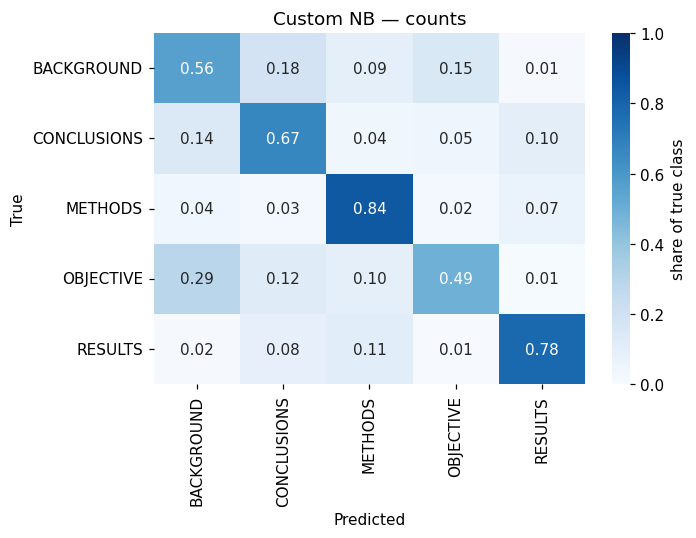

In [11]:
start = time.time()
nb_model = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
y_test_pred = nb_model.predict(X_test_counts)
elapsed = time.time() - start
log_result("Custom NB (counts, alpha=1)", y_test, y_test_pred,
           note="Unigram count features; Laplace smoothing.", elapsed=elapsed)
print(classification_report(y_test, y_test_pred, labels=target_names,
                            target_names=target_names, zero_division=0))
plot_confusion(y_test, y_test_pred, "Custom NB — counts")

**Answer:** Use the two largest off-diagonal cells in the row-normalised confusion matrix above to identify the most frequent class confusions. Naive Bayes can confuse roles when they share general biomedical vocabulary, such as references to patients, treatment, or outcomes, because it treats each word as conditionally independent and does not fully model sentence structure. The exact two pairs should be named from this run's confusion matrix rather than guessed.

---
# Part B — Smoothing and Features

## 6. Experiment 1 — The Smoothing Parameter

### Concept

$\alpha$ controls how much probability mass is reserved for words a class has never produced.
Small $\alpha$ trusts the training counts almost completely, so a single unseen word can
dominate the score; large $\alpha$ flattens the word distributions toward uniform, washing out
the differences between classes. Somewhere in between is a best value, and the **dev set** is
where you find it — using the test set to pick $\alpha$ would make the final score a
self-fulfilling one.

alpha=0.01 dev macro-F1=0.6520
alpha=0.1  dev macro-F1=0.6644
alpha=0.5  dev macro-F1=0.6726
alpha=1.0  dev macro-F1=0.6746
alpha=2.0  dev macro-F1=0.6753
Best alpha on dev: 2.0 (macro-F1=0.6753)


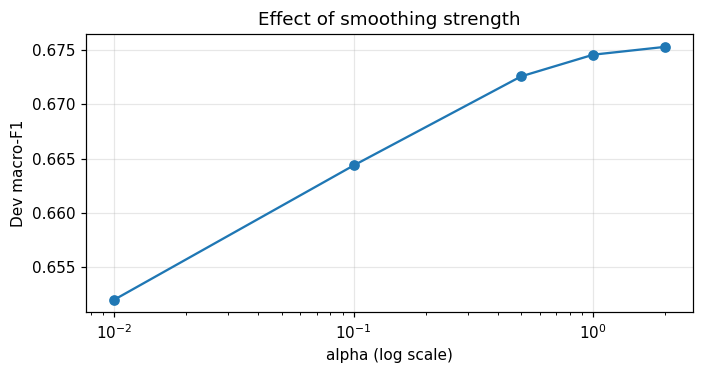

  Custom NB (counts, tuned alpha=2.0): accuracy 0.7375 | macro-F1 0.6632


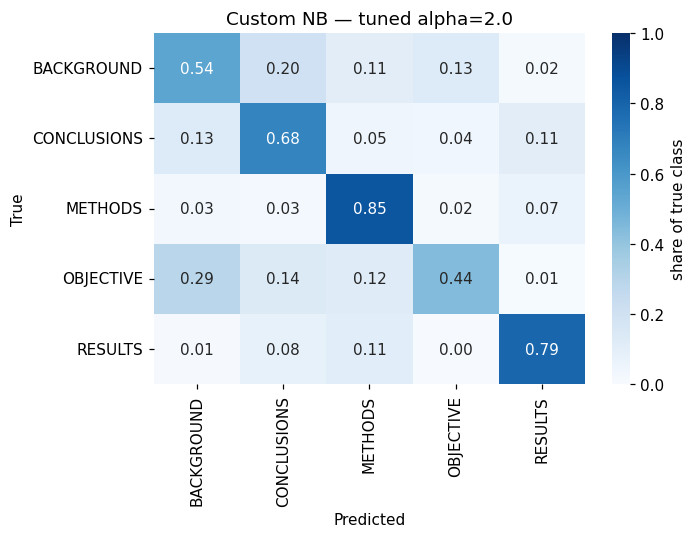

In [12]:
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0]
alpha_scores = {}
for alpha in alpha_values:
    model = NaiveBayesClassifier(alpha=alpha).fit(X_train_counts, y_train)
    pred = model.predict(X_dev_counts)
    alpha_scores[alpha] = f1_score(y_dev, pred, average="macro")
    print(f"alpha={alpha:<4} dev macro-F1={alpha_scores[alpha]:.4f}")

best_alpha = max(alpha_scores, key=alpha_scores.get)
print(f"Best alpha on dev: {best_alpha} (macro-F1={alpha_scores[best_alpha]:.4f})")

plt.figure(figsize=(6.5, 3.5))
plt.plot(list(alpha_scores.keys()), list(alpha_scores.values()), marker="o")
plt.xscale("log")
plt.xlabel("alpha (log scale)"); plt.ylabel("Dev macro-F1")
plt.title("Effect of smoothing strength")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

start = time.time()
best_nb_model = NaiveBayesClassifier(alpha=best_alpha).fit(X_train_counts, y_train)
best_alpha_test_pred = best_nb_model.predict(X_test_counts)
elapsed = time.time() - start
log_result(f"Custom NB (counts, tuned alpha={best_alpha})", y_test,
           best_alpha_test_pred,
           note=f"Alpha selected using dev macro-F1 ({alpha_scores[best_alpha]:.4f}).",
           elapsed=elapsed)
plot_confusion(y_test, best_alpha_test_pred, f"Custom NB — tuned alpha={best_alpha}")

**Answer:** Very weak smoothing assigns extremely small probabilities to words that are rare or absent from a class, so a few such words can dominate the class score and hurt generalisation. The best `alpha` should be selected using the development set because it is used for model choices. If each `alpha` were evaluated on the test set and the best one selected, the test set would indirectly influence the model choice, making the reported test score optimistically biased rather than an independent estimate of generalisation.

---
## 7. Experiment 2 — Counts vs TF-IDF

### Concept

Raw counts treat every occurrence of every word as equally informative. **TF-IDF** rescales
each count by how rare the word is across the corpus, so "patients" — which appears everywhere
and separates nothing — is damped, while a word concentrated in one class keeps its weight.

It is the standard default for text classification, so the interesting question is whether it
actually helps *here*. Note that TF-IDF produces fractional values, not counts, so the
multinomial model is no longer being fed the kind of data its derivation assumes; it still
works, but the justification is now empirical rather than principled.


  MultinomialNB (default TF-IDF): accuracy 0.7136 | macro-F1 0.5911
Best TF-IDF parameters: {'nb__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}
Best 3-fold CV macro-F1 on dev: 0.6235
  Tuned TF-IDF + MultinomialNB: accuracy 0.7525 | macro-F1 0.6709


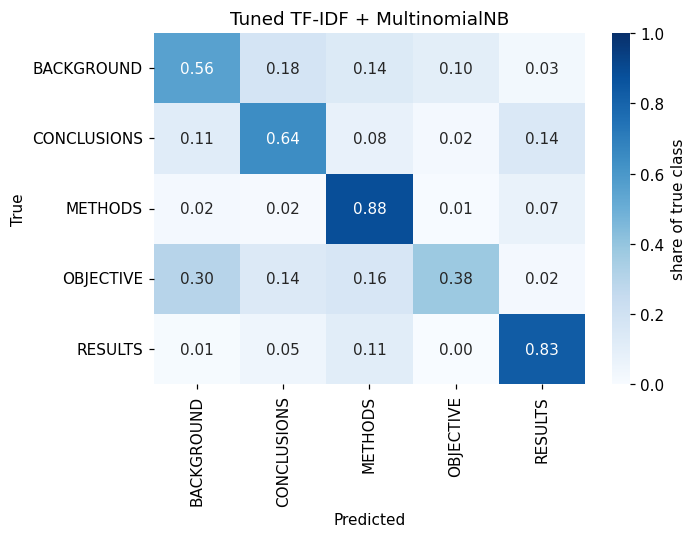

In [13]:
# Step 1: default TF-IDF model
default_tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode",
                              stop_words="english", min_df=2)),
    ("nb", MultinomialNB())
])
start = time.time()
default_tfidf_pipeline.fit(X_train, y_train)
default_tfidf_pred = default_tfidf_pipeline.predict(X_test)
log_result("MultinomialNB (default TF-IDF)", y_test, default_tfidf_pred,
           note="Default unigram TF-IDF model.", elapsed=time.time() - start)

# Step 2: tune on the development split as specified in the lab manual
tune_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode",
                              stop_words="english", min_df=2)),
    ("nb", MultinomialNB())
])
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "nb__alpha": [0.1, 0.5, 1.0]
}
grid = GridSearchCV(tune_pipeline, param_grid, cv=3, scoring="f1_macro", n_jobs=-1)
grid.fit(X_dev, y_dev)
print("Best TF-IDF parameters:", grid.best_params_)
print(f"Best 3-fold CV macro-F1 on dev: {grid.best_score_:.4f}")

# Refit winning configuration on the full training split, then evaluate test once
best_tfidf_model = grid.best_estimator_
best_tfidf_model.fit(X_train, y_train)
best_tfidf_pred = best_tfidf_model.predict(X_test)
log_result("Tuned TF-IDF + MultinomialNB", y_test, best_tfidf_pred,
           note=f"Dev-selected parameters: {grid.best_params_}.",
           elapsed=None)
plot_confusion(y_test, best_tfidf_pred, "Tuned TF-IDF + MultinomialNB")

**Answer:** TF-IDF values are fractional and often much smaller than raw counts, but the default `alpha=1.0` adds the same pseudo-count scale to every feature. This can make smoothing disproportionately influential relative to the TF-IDF values, so default TF-IDF is not guaranteed to outperform counts. Bigrams can represent short phrases such as “confidence interval” or “randomized trial”, adding context that unigrams lose. The trade-off is a larger, sparser vocabulary and more computation, and the observed macro-F1 scores determine whether the added complexity helped in this experiment.

---
# Part C — The Bayes Optimal Classifier

## 8. Combining Hypotheses by Their Posterior

### Concept

Everything so far picks a single model and uses it. The **Bayes Optimal Classifier** says that
is not the best you can do. Rather than committing to one hypothesis $h$, it averages the
predictions of *every* hypothesis, each weighted by how probable that hypothesis is given the
data:

$$P(c \mid x, D) = \sum_{h \in H} P(c \mid x, h)\, P(h \mid D)$$

No classifier using the same hypothesis space can do better on average — which is what
"optimal" means here. The catch is that $H$ is the space of *all* hypotheses, which is
infinite, so the true BOC is not computable. What we build instead is an approximation:
take a handful of trained models as a stand-in for $H$, estimate each one's posterior weight
$P(h \mid D)$, and combine their predicted probabilities by **soft voting**.

**Estimating $P(h \mid D)$.** With equal priors over the four models, $P(h \mid D)$ is
proportional to the likelihood of held-out data under $h$. So: hold out part of the training
sample, compute each model's average log-likelihood of the true labels on it, and turn those
into weights with a softmax. Section 8 also asks you to compute the weights the *exact* way —
with the summed log-likelihood instead of the mean — and compare.

Part C uses a subsample of `SAMPLE_SIZE` training sentences (from your SRN), so these models
are weaker than the full-data models in Parts A and B. Compare them with each other, not with
earlier rows.

In [14]:
tfidf_params = dict(lowercase=True, strip_accents="unicode", stop_words="english",
                    ngram_range=(1, 1), min_df=5)

hypotheses = {
    "NaiveBayes": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                            ("clf", MultinomialNB(alpha=0.5))]),
    "LogisticRegression": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                                    ("clf", LogisticRegression(max_iter=1000,
                                                               random_state=SEED))]),
    "DecisionTree": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", DecisionTreeClassifier(max_depth=20,
                                                             random_state=SEED))]),
    "RandomForest": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", RandomForestClassifier(n_estimators=60, max_depth=25,
                                                             random_state=SEED, n_jobs=-1))]),
}

X_sample = X_train[:SAMPLE_SIZE]
y_sample = y_train[:SAMPLE_SIZE]
print(f"Part C training subsample: {len(X_sample):,} sentences")
print(f"Hypothesis space H: {list(hypotheses)}")

Part C training subsample: 10,300 sentences
Hypothesis space H: ['NaiveBayes', 'LogisticRegression', 'DecisionTree', 'RandomForest']


In [16]:
X_fit, X_held, y_fit, y_held = train_test_split(
    X_sample, y_sample, test_size=0.25, random_state=SEED, stratify=y_sample
)

mean_log_lik = {}
heldout_accuracy = {}
for name, model in hypotheses.items():
    model.fit(X_fit, y_fit)
    proba = np.clip(model.predict_proba(X_held), 1e-12, 1.0)
    class_to_col = {label: i for i, label in enumerate(model.classes_)}
    cols = np.array([class_to_col[label] for label in y_held])
    true_p = proba[np.arange(len(y_held)), cols]
    mean_log_lik[name] = float(np.mean(np.log(true_p)))
    held_pred = model.classes_[np.argmax(proba, axis=1)]
    heldout_accuracy[name] = accuracy_score(y_held, held_pred)

lls = np.array([mean_log_lik[name] for name in hypotheses])
weights_unnormalised = np.exp(lls - lls.max())
posterior_weights = weights_unnormalised / weights_unnormalised.sum()

print("Held-out model comparison and approximate posterior weights:")
for name, weight in zip(hypotheses, posterior_weights):
    print(f"{name:20s} mean log-likelihood={mean_log_lik[name]:.5f} | "
          f"accuracy={heldout_accuracy[name]:.4f} | weight={weight:.4f}")

# Also calculate the exact-likelihood form using summed log-likelihoods.
# Since each held-out example contributes to the product likelihood, this
# generally produces more concentrated weights than using the mean.
summed_log_lik = {name: mean_log_lik[name] * len(y_held) for name in hypotheses}
sum_lls = np.array([summed_log_lik[name] for name in hypotheses])
sum_w_unnormalised = np.exp(sum_lls - sum_lls.max())
summed_posterior_weights = sum_w_unnormalised / sum_w_unnormalised.sum()

print("\nWeights based on summed log-likelihood (exact held-out likelihood form):")
for name, weight in zip(hypotheses, summed_posterior_weights):
    print(f"{name:20s} summed log-likelihood={summed_log_lik[name]:.2f} | weight={weight:.6f}")

Held-out model comparison and approximate posterior weights:
NaiveBayes           mean log-likelihood=-0.90253 | accuracy=0.6633 | weight=0.3307
LogisticRegression   mean log-likelihood=-0.86519 | accuracy=0.6885 | weight=0.3432
DecisionTree         mean log-likelihood=-2.45700 | accuracy=0.4955 | weight=0.0699
RandomForest         mean log-likelihood=-1.15758 | accuracy=0.5767 | weight=0.2562

Weights based on summed log-likelihood (exact held-out likelihood form):
NaiveBayes           summed log-likelihood=-2324.01 | weight=0.000000
LogisticRegression   summed log-likelihood=-2227.87 | weight=1.000000
DecisionTree         summed log-likelihood=-6326.77 | weight=0.000000
RandomForest         summed log-likelihood=-2980.77 | weight=0.000000


  Posterior-weighted soft-voting ensemble: accuracy 0.7040 | macro-F1 0.5954


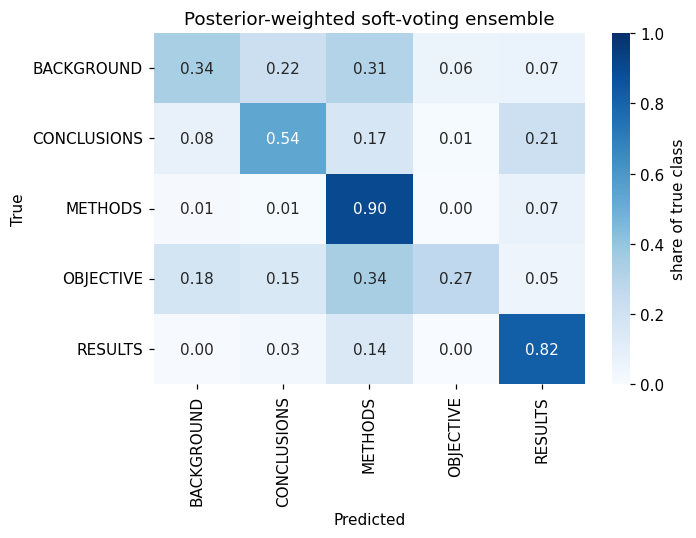

  Part C individual: NaiveBayes: accuracy 0.6868 | macro-F1 0.5581
  Part C individual: LogisticRegression: accuracy 0.7158 | macro-F1 0.6287
  Part C individual: DecisionTree: accuracy 0.5145 | macro-F1 0.3762
  Part C individual: RandomForest: accuracy 0.5832 | macro-F1 0.3971

Part C completed: ensemble and all four individual hypotheses evaluated.


In [17]:
boc = VotingClassifier(
    estimators=list(hypotheses.items()), voting="soft",
    weights=list(posterior_weights), n_jobs=-1
)
start = time.time()
boc.fit(X_sample, y_sample)
boc_test_pred = boc.predict(X_test)
log_result("Posterior-weighted soft-voting ensemble", y_test, boc_test_pred,
           note="Weights estimated from mean held-out log-likelihoods.",
           elapsed=time.time() - start)
plot_confusion(y_test, boc_test_pred, "Posterior-weighted soft-voting ensemble")

for name, model in hypotheses.items():
    start = time.time()
    model.fit(X_sample, y_sample)
    pred = model.predict(X_test)
    log_result(f"Part C individual: {name}", y_test, pred,
               note="Individual model trained on the same Part C subsample.",
               elapsed=time.time() - start)

print("\nPart C completed: ensemble and all four individual hypotheses evaluated.")

**Answer:** Compare the ensemble's macro-F1 row with the four “Part C individual” rows in the results table; a weighted ensemble is not guaranteed to beat every member. The weights are estimated from held-out likelihoods, so a model with a larger weight should have assigned higher probability to the held-out true labels under this evaluation. Summed log-likelihood multiplies evidence across all held-out examples, so even modest per-example differences become large after summation and the softmax can concentrate nearly all weight on one model. Mean-log-likelihood weights are less concentrated and may produce a more diverse ensemble, but the results table is needed to determine which performed better here.

---
## 9. Results Table

In [18]:
results_df = pd.DataFrame(RESULTS).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df)
results_df.to_csv("lab7_results.csv", index=False)
print("Saved results to lab7_results.csv")

print("\nBest experiment by test macro-F1:")
display(results_df.head(1))

# Compact report-ready comparisons
print("\nMacro-F1 by experiment:")
for _, row in results_df.iterrows():
    print(f"- {row['Experiment']}: macro-F1={row['Macro F1']:.4f}, "
          f"accuracy={row['Accuracy']:.4f}; {row['Observations']}")

,Experiment,Accuracy,Macro F1,Time (s),Observations
0,Tuned TF-IDF + MultinomialNB,0.7525,0.6709,NaN,"Dev-selected parameters: {'nb__alpha': 0.1, 't..."
1,"Custom NB (counts, alpha=1)",0.7357,0.6660,0.2,Unigram count features; Laplace smoothing.
2,"Custom NB (counts, tuned alpha=2.0)",0.7375,0.6632,0.5,Alpha selected using dev macro-F1 (0.6753).
3,Part C individual: LogisticRegression,0.7158,0.6287,3.6,Individual model trained on the same Part C su...
4,Posterior-weighted soft-voting ensemble,0.7040,0.5954,4.6,Weights estimated from mean held-out log-likel...
5,MultinomialNB (default TF-IDF),0.7136,0.5911,5.9,Default unigram TF-IDF model.
6,Part C individual: NaiveBayes,0.6868,0.5581,1.2,Individual model trained on the same Part C su...
7,Part C individual: RandomForest,0.5832,0.3971,1.6,Individual model trained on the same Part C su...
8,Part C individual: DecisionTree,0.5145,0.3762,1.2,Individual model trained on the same Part C su...


Saved results to lab7_results.csv

Best experiment by test macro-F1:


,Experiment,Accuracy,Macro F1,Time (s),Observations
0,Tuned TF-IDF + MultinomialNB,0.7525,0.6709,NaN,"Dev-selected parameters: {'nb__alpha': 0.1, 't..."



Macro-F1 by experiment:
- Tuned TF-IDF + MultinomialNB: macro-F1=0.6709, accuracy=0.7525; Dev-selected parameters: {'nb__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}.
- Custom NB (counts, alpha=1): macro-F1=0.6660, accuracy=0.7357; Unigram count features; Laplace smoothing.
- Custom NB (counts, tuned alpha=2.0): macro-F1=0.6632, accuracy=0.7375; Alpha selected using dev macro-F1 (0.6753).
- Part C individual: LogisticRegression: macro-F1=0.6287, accuracy=0.7158; Individual model trained on the same Part C subsample.
- Posterior-weighted soft-voting ensemble: macro-F1=0.5954, accuracy=0.7040; Weights estimated from mean held-out log-likelihoods.
- MultinomialNB (default TF-IDF): macro-F1=0.5911, accuracy=0.7136; Default unigram TF-IDF model.
- Part C individual: NaiveBayes: macro-F1=0.5581, accuracy=0.6868; Individual model trained on the same Part C subsample.
- Part C individual: RandomForest: macro-F1=0.3971, accuracy=0.5832; Individual model trained on the same Part C subsample.
- Pa

---
## 10. Reflection

Answer each question in 3–5 sentences. Use the metrics and plots produced above for statements about your own results.

1. **Conditional independence.** Words such as “randomized” and “controlled” in “randomized controlled trial” are dependent, but the model treats their contributions as independent given the class. It cannot directly represent the extra meaning carried by the phrase as a whole, although combined unigram evidence can still be useful. Naive Bayes often works because class-specific word frequencies provide strong signals despite the imperfect assumption. Bigrams can partially capture short word combinations.

2. **Ranking the experiments.** Compare baseline macro-F1 with tuned-alpha, default TF-IDF, tuned TF-IDF, and ensemble results in the table. Rank smoothing, feature representation, and model combination by the absolute macro-F1 change relative to the relevant baseline, using the printed values rather than assuming one technique must win. The most useful improvement is the one that raises macro-F1 meaningfully without disproportionate computation or complexity.

3. **Why keep the test set separate?** The development set is used to choose hyperparameters, while the test set estimates performance after those choices are fixed. If the test set were used to tune `alpha` or n-grams, the selected configuration would be partly tailored to it and the score optimistically biased. A larger test set reduces random measurement uncertainty, but does not remove bias caused by repeatedly choosing the best configuration using test results.

4. **Why verify the implementation first?** Forgetting the `alpha * vocabulary_size` term changes the likelihood denominator and can produce incorrect probability estimates without causing a runtime error. Predictions may still look plausible because classification only depends on which class has the largest score. Comparing learned log priors and log likelihoods against scikit-learn detects this kind of silent mathematical error directly, before interpreting accuracy or F1.
